# Checkpoint 1: First Results and Plan Revision

**Research question:** Among U.S. Craigslist listings in April-May 2021, is the adjusted dollar decline in listing price per additional 10,000 miles smaller for pickups than for sedans, accounting for vehicle age, manufacturer, condition, transmission, and drivetrain?

## 1. Progress Against Proposal

Our proposal committed us to loading and cleaning the pickup/sedan listings, documenting missing and implausible values, creating vehicle-age and 10,000-mile mileage measures, and producing a cleaned dataset and exploratory summaries. We completed these steps for 119,016 listings (40,481 pickups and 78,535 sedans) and exported the cleaned dataset. A fresh download from the proposal's Kaggle source reproduces the original dimensions and group counts; we retain the original question and document the cleaning and missing-data assumptions that need further checks.


## 2. Method Implemented

### Data and workflow

We use the `vehicles.csv` file from Austin Reese's [Used Cars Dataset on Kaggle](https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data), the source linked in our proposal. The source has 426,880 listings and 26 columns; we load the 12 columns needed for analysis, date checks, and listing/vehicle identification. We retain the exact `pickup` and `sedan` categories, giving 130,566 listings before numeric cleaning; the separate `truck` category is outside our stated subset. Non-missing posting dates fall in April-May 2021, and none of the pickup/sedan listings lacks a posting date.

Each observation is one listing, not necessarily one unique vehicle. We check listing URLs and IDs for duplication and separately count repeated non-missing VINs. We retain distinct listings, but repeated vehicles can give some vehicles extra weight and will require a sensitivity check before statistical inference.

### Preprocessing and representation

| Step | Input and rule | Output and reason |
|---|---|---|
| Date and type selection | Raw listings; keep observed dates and exact pickup/sedan labels | Listings in the proposed period and categories |
| Required numeric fields | Exclude missing price, odometer, or model year | Records with observed outcome, mileage, and age inputs |
| Price restriction | Keep $101-$100,000, inclusive | Remove very low placeholder-like prices and extreme prices; some genuine listings may be excluded |
| Mileage restriction | Keep 1-400,000 miles, inclusive | Remove nonpositive readings and extreme mileage while retaining plausible high-mileage vehicles |
| Model-year restriction | Keep 1900-2021, inclusive | Define nonnegative model-year age relative to 2021; 2022 models can exist in 2021 but are outside this age definition |
| Missing categories | Replace missing manufacturer, condition, transmission, and drive with `unknown` | Preserve listings and record missing information explicitly |
| Derived features | Age = 2021 minus model year; mileage = odometer divided by 10,000 | Comparable age and mileage units for the planned model |

The 300,000-mile diagnostic is a flag for inspection, not the exclusion threshold. The final ceiling is 400,000 miles to preserve high-mileage listings relevant to the question; its influence remains to be checked. Pre-1990 vehicles are retained rather than assumed erroneous, but their price relationship may differ from ordinary used vehicles. These are preliminary analytic restrictions, not proof that every retained value is valid or every excluded value is an error. The sequential audit below applies the same final rules and counts each excluded listing once.

The resulting table has 119,016 listings and 11 columns, including the ID. Labeling missing categories `unknown` does not recover their values; we retain this category for later encoding rather than interpolating nominal labels.

### Analysis completed and connection to the question

We calculate counts, missing-value totals, quantiles, and group summaries, then compare listing price, mileage, and age between pickups and sedans. The cleaned listing table is the input; the outputs are a cleaning audit, group comparison table, and exploratory mileage-price figure. These summaries check whether the proposed comparison is feasible and expose distribution differences; they do not estimate the adjusted mileage effect. The multiple linear regression and mileage-by-type interaction remain the next checkpoint's analysis.

### Reproducibility

Run this notebook from the `checkpoint1` directory with the Kaggle file at `data/vehicles.csv` (or `vehicles.csv`). The download source and SHA-256 are recorded in `data/source.json`. The notebook exports the cleaned data and audit locally; raw archives and CSVs are excluded from Git because of their size.

### Supporting workflow


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display


The following cells implement the documented selection and cleaning workflow, with diagnostics retained for review.

In [2]:
data_path = Path("data/vehicles.csv")
if not data_path.exists():
    data_path = Path("vehicles.csv")
if not data_path.exists():
    raise FileNotFoundError("Download vehicles.csv from the linked Kaggle dataset into checkpoint1/data/.")
raw_columns = pd.read_csv(data_path, nrows=0).columns.tolist()
required_columns = ["id", "url", "VIN", "posting_date", "price", "odometer", "year", "manufacturer", "condition", "transmission", "drive", "type"]
df = pd.read_csv(data_path, usecols=required_columns)


The dataset is loaded into `df`.

In [3]:
print("Raw source dimensions:", (len(df), len(raw_columns)))
print("Loaded columns:", df.shape[1])
print("Raw columns:", raw_columns)
display(df.head())
df.dtypes


Raw source dimensions: (426880, 26)
Loaded columns: 12
Raw columns: ['id', 'url', 'region', 'region_url', 'price', 'year', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'odometer', 'title_status', 'transmission', 'VIN', 'drive', 'size', 'type', 'paint_color', 'image_url', 'description', 'county', 'state', 'lat', 'long', 'posting_date']


,id,url,price,year,manufacturer,condition,odometer,transmission,VIN,drive,type,posting_date
0,7222695916,https://prescott.craigslist.org/cto/d/prescott...,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,7218891961,https://fayar.craigslist.org/ctd/d/bentonville...,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,7221797935,https://keys.craigslist.org/cto/d/summerland-k...,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,7222270760,https://worcester.craigslist.org/cto/d/west-br...,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,7210384030,https://greensboro.craigslist.org/cto/d/trinit...,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


id                int64
url              object
price             int64
year            float64
manufacturer     object
condition        object
odometer        float64
transmission     object
VIN              object
drive            object
type             object
posting_date     object
dtype: object

Inspect source dimensions, column names, and loaded data types before selecting the study subset. Unneeded text and image fields are not loaded into memory.

In [4]:
print("Duplicate URLs:", df["url"].duplicated().sum())
print("Repeated non-missing VIN occurrences:", df["VIN"].dropna().duplicated().sum())
print("Missing VINs:", df["VIN"].isna().sum())


Duplicate URLs: 0
Repeated non-missing VIN occurrences: 147574
Missing VINs: 161042


The saved source has no duplicate listing URLs. VIN identifies a vehicle rather than a listing, and many VINs are missing. We retain distinct listings under the proposal's observation definition and count repeated VINs only after excluding missing values. Repeated vehicles remain a potential source of unequal weighting and dependence.

In [5]:
print(
    df["posting_date"]
    .astype("string")
    .str[:7]
    .value_counts()
    .sort_index()
)

posting_date
2021-04    316969
2021-05    109843
Name: count, dtype: Int64


The non-missing source dates are April-May 2021: 316,969 listings in April and 109,843 in May. This matches the proposal's period.

In [6]:
print(df["posting_date"].isna().sum())

68


Check missing posting dates before applying the period restriction.

In [7]:
print(
    df[df["type"].isin(["pickup", "sedan"])]["posting_date"].isna().sum()
)

0


There are 68 missing posting dates in the source; none belongs to the pickup/sedan subset.

In [8]:
observed_months = set(df["posting_date"].dropna().str[:7].unique())
assert observed_months <= {"2021-04", "2021-05"}, "Source period changed; review the date restriction."
df = df.dropna(subset=["posting_date"])


Records with missing `posting_date` are removed because we are not sure if they were made between April and May 2021. No other date filter is needed because the observed non-missing dates are already April or May 2021.

In [9]:
print(df["posting_date"].isna().sum())

0


The follow-up check confirms that the working dataset has no missing posting dates after the exclusion.

In [10]:
subset_columns = df[["id","price", "odometer", "year", "manufacturer", "condition", "transmission", "drive", "type"]]

Select the listing ID and the eight research variables. Price and odometer are numerical; model year supplies model-year age; manufacturer, condition, transmission, drive, and type are categorical.

In [11]:
subset_type = subset_columns[
    subset_columns["type"].isin(["pickup", "sedan"])
]

Restrict listings to the exact `pickup` and `sedan` labels. The separate `truck` category is excluded to preserve the proposal's category definition.

In [12]:
print("Duplicate IDs:", subset_type["id"].duplicated().sum())

Duplicate IDs: 0


There are no duplicate listing IDs in the selected subset. Matching non-identifier fields alone do not establish duplicate listings, particularly when categorical information is missing.

In [13]:
print(subset_type["type"].value_counts(dropna=False))
print(subset_type.isna().sum())
print(subset_type[["price", "odometer", "year"]].describe())

type
sedan     87056
pickup    43510
Name: count, dtype: int64
id                  0
price               0
odometer         1542
year              578
manufacturer     3011
condition       44092
transmission      599
drive           28275
type                0
dtype: int64
              price      odometer           year
count  1.305660e+05  1.290240e+05  129988.000000
mean   5.887217e+04  8.804216e+04    2012.435240
std    1.081098e+07  1.585760e+05       7.830641
min    0.000000e+00  0.000000e+00    1923.000000
25%    6.350000e+03  3.433750e+04    2010.000000
50%    1.482800e+04  7.761300e+04    2014.000000
75%    2.699800e+04  1.245320e+05    2017.000000
max    3.736929e+09  1.000000e+07    2022.000000


These outputs describe group sizes, missingness, and numeric distributions before cleaning. Zero and extreme values require inspection before analysis.

In [14]:
numeric_cols = ["price", "odometer", "year"]
display(subset_type[numeric_cols].quantile([0, 0.01, 0.05, 0.50, 0.95, 0.99, 0.995, 0.999, 1]))
for column in numeric_cols:
    print(f"\n{column}")
    print(subset_type.nlargest(10, column)[["type", "price", "odometer", "year"]])


,price,odometer,year
0.000,0.000000e+00,0.00,1923.0
0.010,0.000000e+00,129.23,1979.0
0.050,0.000000e+00,8522.15,2001.0
0.500,1.482800e+04,77613.00,2014.0
0.950,4.259000e+04,193236.80,2019.0
0.990,6.299500e+04,254252.00,2020.0
0.995,6.998100e+04,280000.00,2020.0
0.999,8.790000e+04,510065.00,2021.0
1.000,3.736929e+09,10000000.00,2022.0



price
          type       price   odometer    year
318592  pickup  3736928711   164000.0  2007.0
29386   pickup  1111111111   149000.0  1999.0
137807   sedan   123456789    96000.0  1999.0
193736   sedan   123456789    64181.0  2015.0
207080  pickup   123456789  1234567.0  2003.0
307488  pickup   123456789   320000.0  1996.0
136516  pickup    17000000   170000.0  2007.0
327938   sedan     3226714     1234.0  2002.0
68935    sedan     2000000   164290.0  2002.0
208617  pickup      554900    25365.0  2019.0

odometer
          type  price    odometer    year
144436   sedan   4500  10000000.0  2010.0
151740   sedan    800  10000000.0  1949.0
262338  pickup   4800  10000000.0  1949.0
287115   sedan      0  10000000.0  1995.0
292399   sedan   1300  10000000.0  1950.0
305172   sedan   4500  10000000.0  1995.0
27200    sedan   1500   9999999.0  1989.0
217319  pickup   6500   9999999.0  1941.0
217320  pickup   5500   9999999.0  1939.0
219681   sedan    900   9999999.0  1993.0

year
         

Inspect percentiles and large observations before choosing analytic bounds. Billion-dollar prices and odometer readings near 10 million miles indicate data-quality problems; less extreme observations still require judgment.

In [15]:
rules = {
    "nonpositive price": subset_type["price"] <= 0,
    "nonpositive odometer": subset_type["odometer"] <= 0,
    "year after 2021": subset_type["year"] > 2021,
    "year before 1990": subset_type["year"] < 1990,
    "price above 100,000": subset_type["price"] > 100_000,
    "odometer above 300,000": subset_type["odometer"] > 300_000,
}

pd.Series({name: rule.sum() for name, rule in rules.items()})

nonpositive price         8871
nonpositive odometer       397
year after 2021              2
year before 1990          1920
price above 100,000         60
odometer above 300,000     418
dtype: int64

These diagnostic counts overlap and must not be summed as sequential exclusions. Nonpositive includes zero. Mileage above 300,000 and model years before 1990 are inspection flags; the final retained limits are documented separately.

In [16]:
subset_type.duplicated().sum()

np.int64(0)

In [17]:
subset_type.groupby("type")[["price", "odometer", "year"]].quantile(
    [0.01, 0.05, 0.50, 0.95, 0.99, 0.995, 0.999]
)

price    odometer      year
type                                         
pickup 0.010      0.000     102.000  1973.000
       0.050      1.000    7663.050  2000.000
       0.500  27990.000   71288.000  2015.000
       0.950  54466.000  211000.000  2020.000
       0.990  71995.000  274820.000  2020.000
       0.995  78981.000  307085.785  2020.365
       0.999  89900.000  999999.000  2021.000
sedan  0.010      0.000     160.000  1986.000
       0.050      0.000    8973.000  2002.000
       0.500   9995.000   79983.000  2014.000
       0.950  34947.000  184443.750  2019.000
       0.990  44000.000  234205.950  2020.000
       0.995  49995.000  260000.000  2020.000
       0.999  80942.165  400000.000  2021.000

We find quantiles for both pickups and sedans because the two vehicle types can have different price and mileage distributions. The results show that a price ceiling of $100,000 is above the 99.9th percentile for both groups.

In [18]:
subset_type.loc[
    (subset_type["price"] > 100_000) | (subset_type["odometer"] > 300_000),
    ["type", "price", "odometer", "year"]
].sort_values(["price", "odometer"], ascending=False).head(30)

,type,price,odometer,year
318592,pickup,3736928711,164000.0,2007.0
29386,pickup,1111111111,149000.0,1999.0
207080,pickup,123456789,1234567.0,2003.0
307488,pickup,123456789,320000.0,1996.0
137807,sedan,123456789,96000.0,1999.0
193736,sedan,123456789,64181.0,2015.0
136516,pickup,17000000,170000.0,2007.0
327938,sedan,3226714,1234.0,2002.0
68935,sedan,2000000,164290.0,2002.0
208617,pickup,554900,25365.0,2019.0


In [19]:
cleaned = subset_type.copy()

cleaned = cleaned.loc[
    cleaned["price"].between(101, 100_000)
    & cleaned["odometer"].between(1, 400_000)
    & cleaned["year"].between(1900, 2021)
].copy()

categorical_cols = ["manufacturer", "condition", "transmission", "drive"]
cleaned[categorical_cols] = cleaned[categorical_cols].fillna("unknown")

cleaned["vehicle_age"] = 2021 - cleaned["year"]
cleaned["odometer_10k"] = cleaned["odometer"] / 10_000

### Final cleaning decisions

Apply the inclusive bounds stated in Section 2. Missing required numerical values fail these bounds and are excluded. Missing categorical values have already been replaced with `unknown`; no interpolation is planned. The 2021 reference year gives model-year age, and each unit of `odometer_10k` represents 10,000 miles.

In [20]:
print(cleaned.shape)
print(cleaned.isna().sum())
print(cleaned["type"].value_counts())
print(cleaned[["price", "odometer", "vehicle_age", "odometer_10k"]].describe())

cleaned.groupby("type")[["price", "odometer", "vehicle_age", "odometer_10k"]].describe()

(119016, 11)
id              0
price           0
odometer        0
year            0
manufacturer    0
condition       0
transmission    0
drive           0
type            0
vehicle_age     0
odometer_10k    0
dtype: int64
type
sedan     78535
pickup    40481
Name: count, dtype: int64
               price       odometer    vehicle_age   odometer_10k
count  119016.000000  119016.000000  119016.000000  119016.000000
mean    19059.832502   85900.689277       8.667793       8.590069
std     13796.877490   60119.054091       7.876928       6.011905
min       101.000000       1.000000       0.000000       0.000100
25%      7800.000000   34375.000000       4.000000       3.437500
50%     15995.000000   78781.000000       7.000000       7.878100
75%     27990.000000  125957.000000      11.000000      12.595700
max     99999.000000  400000.000000      98.000000      40.000000


price                                                                \
          count          mean           std    min      25%      50%      75%   
type                                                                            
pickup  40481.0  28496.301598  14369.891345  123.0  18995.0  27995.0  35995.0   
sedan   78535.0  14195.788375  10605.553952  101.0   6000.0  10999.0  19990.0   

                odometer                ... vehicle_age       odometer_10k  \
            max    count          mean  ...         75%   max        count   
type                                    ...                                  
pickup  99999.0  40481.0  85517.186384  ...        10.0  98.0      40481.0   
sedan   99950.0  78535.0  86098.366499  ...        12.0  97.0      78535.0   

                                                                 
            mean       std     min     25%     50%    75%   max  
type                                                             
pickup  8.551719  6.729232  0.0001  2.7715  7.0559  13.20  40.0  
sedan   8.609837  5.606369  0.0001  3.8867  8.1675  12.37  40.0  

[2 rows x 32 columns]

The saved validation output contains 119,016 listings: 40,481 pickups and 78,535 sedans. There are 11 columns, including the listing ID and the two derived features. Missing categorical values have been labeled `unknown`; this does not recover the original information.

In [21]:
lower_tail = {
    "price <= $100": (cleaned["price"] <= 100).sum(),
    "price <= $500": (cleaned["price"] <= 500).sum(),
    "odometer <= 100": (cleaned["odometer"] <= 100).sum(),
    "odometer <= 500": (cleaned["odometer"] <= 500).sum(),
}
display(pd.Series(lower_tail, name="listings"))
cleaned.loc[
    (cleaned["price"] <= 500) | (cleaned["odometer"] <= 100),
    ["type", "price", "odometer", "year", "manufacturer", "condition"]
].head(30)


price <= $100         0
price <= $500      1786
odometer <= 100     606
odometer <= 500    1098
Name: listings, dtype: int64

,type,price,odometer,year,manufacturer,condition
1069,sedan,300,265000.0,1999.0,saturn,fair
2456,pickup,38615,1.0,2021.0,chevrolet,unknown
3501,pickup,38615,1.0,2021.0,chevrolet,unknown
6060,sedan,11992,1.0,2015.0,dodge,unknown
6065,sedan,34999,12.0,2019.0,mini,unknown
6331,sedan,11992,1.0,2015.0,dodge,unknown
6659,sedan,34499,53.0,2019.0,mini,unknown
6693,sedan,11992,1.0,2015.0,dodge,unknown
7042,sedan,34999,12.0,2019.0,mini,unknown
7107,sedan,11992,1.0,2015.0,dodge,unknown


The retained lower tail includes 1,786 prices at or below $500 and 606 odometer readings at or below 100 miles. Some low-mileage listings may be legitimate, but older one-mile readings and very low recent-model prices may be placeholders or payment amounts. We retain them provisionally and will inspect them and compare alternative restrictions. Listings labeled new also require checking against the proposal's used-vehicle scope.

In [22]:
print(pd.Series(lower_tail))

price <= $100         0
price <= $500      1786
odometer <= 100     606
odometer <= 500    1098
dtype: int64


In [23]:
cleaned.to_csv("craigslist_pickup_sedan_cleaned.csv", index=False)
assert len(cleaned) == cleaned["id"].nunique()
assert cleaned[["price", "odometer", "year"]].notna().all().all()
print("Exported cleaned listings:", len(cleaned))


Exported cleaned listings: 119016


The analytic dataset is exported without the pandas index. It supplies the same observations for the next checkpoint's exploratory checks and adjusted price model.

In [24]:
remaining = subset_type.copy()
audit_rows = []
steps = [
    ("Missing required numeric values", lambda x: x[["price", "odometer", "year"]].notna().all(axis=1)),
    ("Price outside $101-$100,000", lambda x: x["price"].between(101, 100_000)),
    ("Odometer outside 1-400,000 miles", lambda x: x["odometer"].between(1, 400_000)),
    ("Model year outside 1900-2021", lambda x: x["year"].between(1900, 2021)),
]
for label, keep_rule in steps:
    before = len(remaining)
    remaining = remaining.loc[keep_rule(remaining)]
    audit_rows.append({"step": label, "removed": before - len(remaining), "remaining": len(remaining)})
cleaning_audit = pd.DataFrame(audit_rows)
assert remaining.index.equals(cleaned.index)
assert cleaning_audit["removed"].sum() == len(subset_type) - len(cleaned)
cleaning_audit.to_csv("cleaning_audit.csv", index=False)
display(cleaning_audit)


,step,removed,remaining
0,Missing required numeric values,2120,128446
1,"Price outside $101-$100,000",8987,119459
2,"Odometer outside 1-400,000 miles",443,119016
3,Model year outside 1900-2021,0,119016


### Sequential cleaning audit

| Exclusion step, in order | Removed at this step | Remaining |
|---|---:|---:|
| Missing required numeric values | 2,120 | 128,446 |
| Price outside $101-$100,000 | 8,987 | 119,459 |
| Odometer outside 1-400,000 miles | 443 | 119,016 |
| Model year outside 1900-2021 | 0 | 119,016 |

Starting subset: 130,566 listings. Total removed: 11,550. Counts depend on the displayed order and do not overlap; a zero in the final row means no additional records fail that rule after earlier exclusions.


## 3. Preliminary Results

### Group comparison

| Measure | Pickups | Sedans |
|---|---:|---:|
| Before numeric cleaning | 43,510 | 87,056 |
| After numeric cleaning | 40,481 | 78,535 |
| Excluded by numeric cleaning | 3,029 (6.96%) | 8,521 (9.79%) |
| Median listing price | $27,995 | $10,999 |
| Mean mileage | 85,517 miles | 86,098 miles |
| Median mileage | 70,559 miles | 81,675 miles |
| Median model-year age | 6 years | 7 years |

The group comparison is computed from the verified Kaggle source. Numeric cleaning retains 119,016 of 130,566 pickup/sedan listings, removing 11,550 (8.85%). The sequential audit records each exclusion once rather than summing overlapping diagnostic flags.

Pickups have a much higher median listing price. Mean mileage is similar between the groups, but the median pickup has 11,116 fewer miles and is one model year younger. These differences make separate group summaries useful and motivate accounting for age and other characteristics before comparing mileage slopes. Higher pickup prices alone do not show that their prices decline less per 10,000 miles.

### Exploratory price-mileage comparison

Figure 1 displays price against mileage in units of 10,000 miles, with the same axes for both groups. A reproducible sample of 3,500 listings per group keeps the points readable; the overlaid medians use all retained listings in 20,000-mile bins with at least 30 observations. These are unadjusted descriptive summaries, not fitted regression effects.


In [25]:
group_summary = cleaned.groupby("type").agg(
    listings=("id", "size"),
    median_price=("price", "median"),
    mean_mileage=("odometer", "mean"),
    median_mileage=("odometer", "median"),
    median_age=("vehicle_age", "median"),
)
group_summary["before_cleaning"] = subset_type.groupby("type").size()
group_summary["removed"] = group_summary["before_cleaning"] - group_summary["listings"]
group_summary["removed_percent"] = 100 * group_summary["removed"] / group_summary["before_cleaning"]
group_summary.to_csv("group_summary.csv")
assert int(group_summary["listings"].sum()) == len(cleaned)
display(group_summary.round(2))


,listings,median_price,mean_mileage,median_mileage,median_age,before_cleaning,removed,removed_percent
type,,,,,,,,
pickup,40481,27995.0,85517.19,70559.0,6.0,43510,3029,6.96
sedan,78535,10999.0,86098.37,81675.0,7.0,87056,8521,9.79


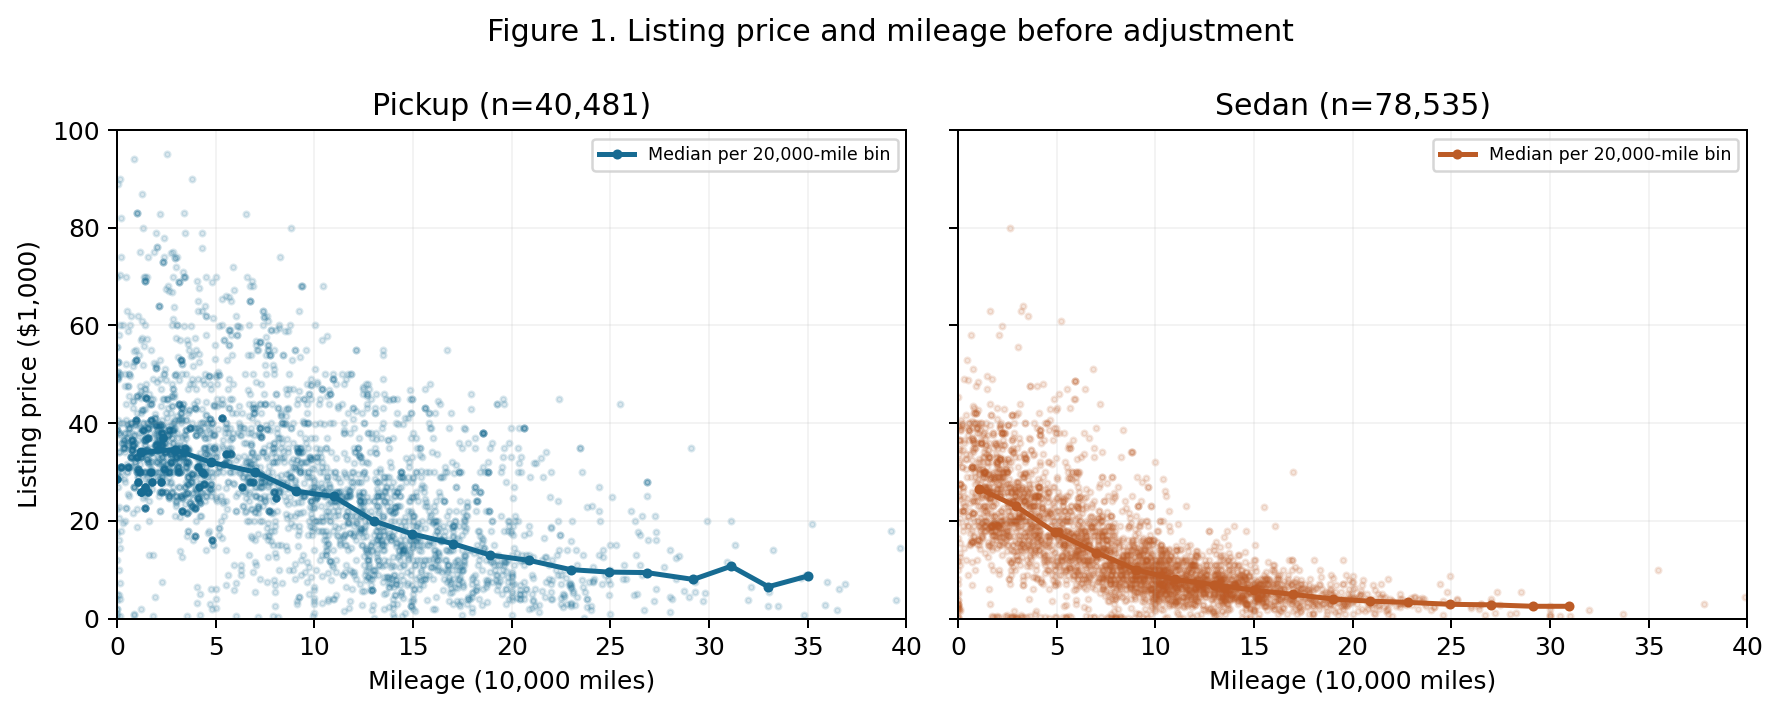

In [26]:
from IPython.display import Image

figure_dir = Path("figures")
figure_dir.mkdir(exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
colors = {"pickup": "#176b92", "sedan": "#bc5b26"}
for ax, vehicle_type in zip(axes, ["pickup", "sedan"]):
    group = cleaned.loc[cleaned["type"].eq(vehicle_type)]
    points = group.sample(n=min(3500, len(group)), random_state=5593)
    ax.scatter(points["odometer_10k"], points["price"] / 1000,
               s=5, alpha=0.15, color=colors[vehicle_type], rasterized=True)
    binned = group.assign(mileage_bin=pd.cut(group["odometer_10k"], np.arange(0, 42, 2), include_lowest=True))
    medians = binned.groupby("mileage_bin", observed=True).agg(
        miles=("odometer_10k", "median"), price=("price", "median"), n=("id", "size"))
    medians = medians.loc[medians["n"].ge(30)]
    ax.plot(medians["miles"], medians["price"] / 1000, color=colors[vehicle_type],
            marker="o", markersize=3, linewidth=2, label="Median per 20,000-mile bin")
    ax.set(title=f"{vehicle_type.title()} (n={len(group):,})", xlabel="Mileage (10,000 miles)", xlim=(0, 40), ylim=(0, 100))
    ax.grid(alpha=0.15)
    ax.legend(fontsize=7, loc="upper right")
axes[0].set_ylabel("Listing price ($1,000)")
fig.suptitle("Figure 1. Listing price and mileage before adjustment", fontsize=12)
fig.tight_layout()
fig.savefig(figure_dir / "price_mileage.png", dpi=180, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(figure_dir / "price_mileage.png")))


Across most mileage bins, median listing prices decrease for both vehicle types, while pickups remain more expensive. The curves flatten at higher mileage and the pickup tail is uneven, so a single constant dollar decline may be an approximation. These exploratory relationships motivate the proposed adjusted comparison, but neither the raw curves nor the price gap establishes that pickups have a smaller adjusted decline per 10,000 miles.


### Limitations and uncertainty

Before numeric cleaning, condition is missing for 44,092 listings (33.77%) and drive for 28,275 (21.66%). An `unknown` category preserves listings but cannot fully account for the missing characteristics. The retained data also include 1,786 prices at or below $500, 606 mileage readings at or below 100 miles, and vehicles up to 98 model years old. These may include unusual genuine listings and reporting errors, so our numeric bounds do not guarantee a homogeneous used-vehicle sample.

Cleaning excludes 9.79% of sedans versus 6.96% of pickups. This difference does not establish bias, but it requires checking whether the comparison depends on filtering choices. Repeated vehicles across distinct listings may also affect weighting and uncertainty. Our evidence concerns asking prices on Craigslist in the specified period, not completed sale prices or the same vehicle losing value over time.

**Course connection:** The group table uses the descriptive statistics and quantiles in the Week 1 reading (pp. 15-23); the figure follows its scatterplot discussion (p. 29). We interpret unusual values as observations to investigate rather than automatically treating every extreme as an error, following Week 1_3 (p. 7).
